<a href="https://colab.research.google.com/github/Maddox159-crypto/2026_ESAA_assignment/blob/main/1113_%EC%84%B8%EC%85%98_RNN_%EC%97%B0%EC%8A%B5%EB%AC%B8%EC%A0%9C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 넷플릭스 주가 예측하기 RNN 코드 실습

## 1. 데이터 가져오기

In [2]:
# 데이터 가져오기
import pandas as pd
data = pd.read_csv("//content/netflix_train.csv")
data.head()
data.head()

,Date,Open,High,Low,Volume,Close
0,2015-12-16,120,123,118,13181000,123
1,2015-12-17,124,126,122,17284900,123
2,2015-12-18,121,122,118,17948100,118
3,2015-12-21,120,120,116,11670000,117
4,2015-12-22,117,117,115,9689000,116


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 967 entries, 0 to 966
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Date    967 non-null    object
 1   Open    967 non-null    int64 
 2   High    967 non-null    int64 
 3   Low     967 non-null    int64 
 4   Volume  967 non-null    int64 
 5   Close   967 non-null    int64 
dtypes: int64(5), object(1)
memory usage: 45.5+ KB


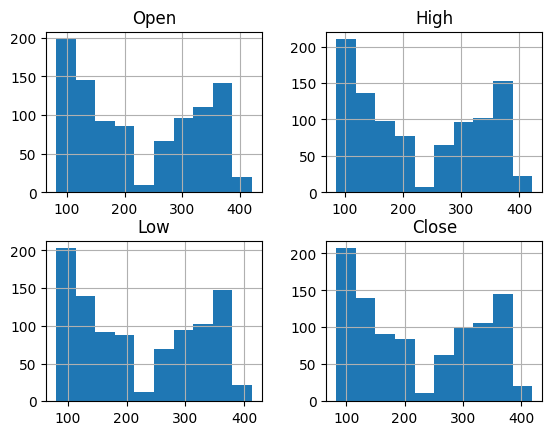

In [4]:
import matplotlib.pyplot as plt

data_used = data.iloc[:, 1:4]        # 개장가, 최고가, 최저가 추가
data_used["Close"] = data["Close"]   # 종가 추가
hist = data_used.hist()
plt.show()

## 2. 파이토치 데이터셋 구성하기

In [6]:
import numpy as np
from torch.utils.data.dataset import Dataset

class Netflix(Dataset):
    def __init__(self):
        # 데이터 읽기
        self.csv = pd.read_csv("/content/netflix_train.csv")

        # 입력 데이터 정규화
        self.data = self.csv.iloc[:, 1:4].values      # 종가를 제외한 데이터
        self.data = self.data / np.max(self.data)     # 0과 1 사이로 정규화

        # 종가 데이터 정규화
        self.label = self.csv["Close"].values
        self.label = self.label / np.max(self.label)

    def __len__(self):
        return len(self.data) - 30   # 사용 가능한 배치 개수

    def __getitem__(self, i):
        data = self.data[i:i+30]     # 입력 데이터 30일치 읽기
        label = self.label[i+30]     # 30일 다음 날의 종가

        return data, label

## 3. RNN 모델 정의

In [7]:
import torch
import torch.nn as nn

class RNN(nn.Module):
    def __init__(self):
        super(RNN, self).__init__()

        # RNN층의 정의
        self.rnn = nn.RNN(input_size=3, hidden_size=8, num_layers=5,
                          batch_first=True)

        # 주가를 예측하는 MLP층 정의
        self.fc1 = nn.Linear(in_features=240, out_features=64)   # 30일 × 은닉 8
        self.fc2 = nn.Linear(in_features=64, out_features=1)

        # 활성화 함수 정의
        self.relu = nn.ReLU()

    # RNN 모델의 순전파 정의
    def forward(self, x, h0):
        x, hn = self.rnn(x, h0)                      # RNN층의 출력

        # MLP층의 입력으로 사용되게 모양 변경
        x = torch.reshape(x, (x.shape[0], -1))

        # MLP층을 이용해 종가 예측
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)

        # 예측한 종가를 1차원 벡터로 표현
        x = torch.flatten(x)

        return x

## 4. 모델 학습하기

In [8]:
import tqdm
from torch.optim.adam import Adam
from torch.utils.data.dataloader import DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"

model = RNN().to(device)   # 모델의 정의
dataset = Netflix()        # 데이터셋의 정의

In [9]:
loader = DataLoader(dataset, batch_size=32)   # 배치 크기를 32로 설정

In [10]:
optim = Adam(params=model.parameters(), lr=0.0001)   # 학습률 0.0001

In [11]:
for epoch in range(200):
    iterator = tqdm.tqdm(loader)
    for data, label in iterator:
        optim.zero_grad()

        # 초기 은닉 상태 (층 개수, 배치 크기, 은닉 크기)
        h0 = torch.zeros(5, data.shape[0], 8).to(device)

        # 모델의 예측값
        pred = model(data.type(torch.FloatTensor).to(device), h0)

        # 손실의 계산
        loss = nn.MSELoss()(pred, label.type(torch.FloatTensor).to(device))
        loss.backward()   # 오차 역전파
        optim.step()      # 최적화 진행

        iterator.set_description(f"epoch{epoch} loss:{loss.item()}")

torch.save(model.state_dict(), "./rnn.pth")   # 모델 저장

epoch199 loss:0.0008234282722696662: 100%|██████████| 30/30 [00:00<00:00, 54.83it/s]


## 5. 모델 성능 평가하기

In [12]:
import matplotlib.pyplot as plt

loader = DataLoader(dataset, batch_size=1)   # 예측값을 위한 데이터로더

preds = []   # 예측값들을 저장하는 리스트
total_loss = 0

with torch.no_grad():
    # 모델의 가중치 불러오기
    model.load_state_dict(torch.load("rnn.pth", map_location=device))

    for data, label in loader:
        h0 = torch.zeros(5, data.shape[0], 8).to(device)   # 초기 은닉 상태 정의

        # 모델의 예측값 출력
        pred = model(data.type(torch.FloatTensor).to(device), h0)
        preds.append(pred.item())   # 예측값을 리스트에 추가

        # 손실 계산
        loss = nn.MSELoss()(pred, label.type(torch.FloatTensor).to(device))

        # 손실의 평균치 계산
        total_loss += loss / len(loader)

total_loss.item()

0.0018149500247091055

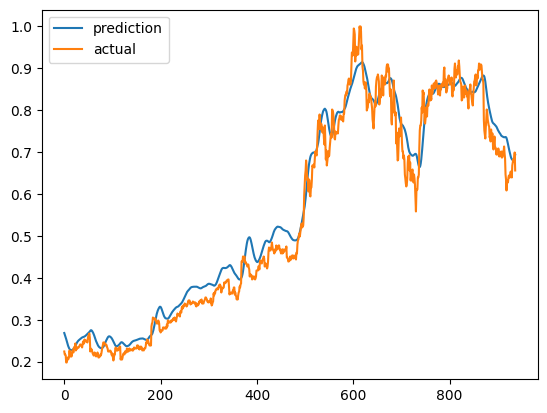

In [13]:
# 그래프 출력
plt.plot(preds, label="prediction")
plt.plot(dataset.label[30:], label="actual")
plt.legend()
plt.show()